<center><h1>Do_Mimi_HW5</h1></center>
<br>
<br>

Name: Mimi Do
<br>
Github Username: mkd222
<br>
USC ID: 8125-6556-10

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
df = pd.read_csv("../data/diagnosis.data", sep = "\t", decimal = ",", encoding = "utf-16", header = None)

df.columns = ["Temperature", "Nausea", "Lumbar Pain", "Urine Pushing", "Micturition Pains", "Urethra Discomfort", "Bladder Inflammation", "Nephritis"]

df.head()

,Temperature,Nausea,Lumbar Pain,Urine Pushing,Micturition Pains,Urethra Discomfort,Bladder Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

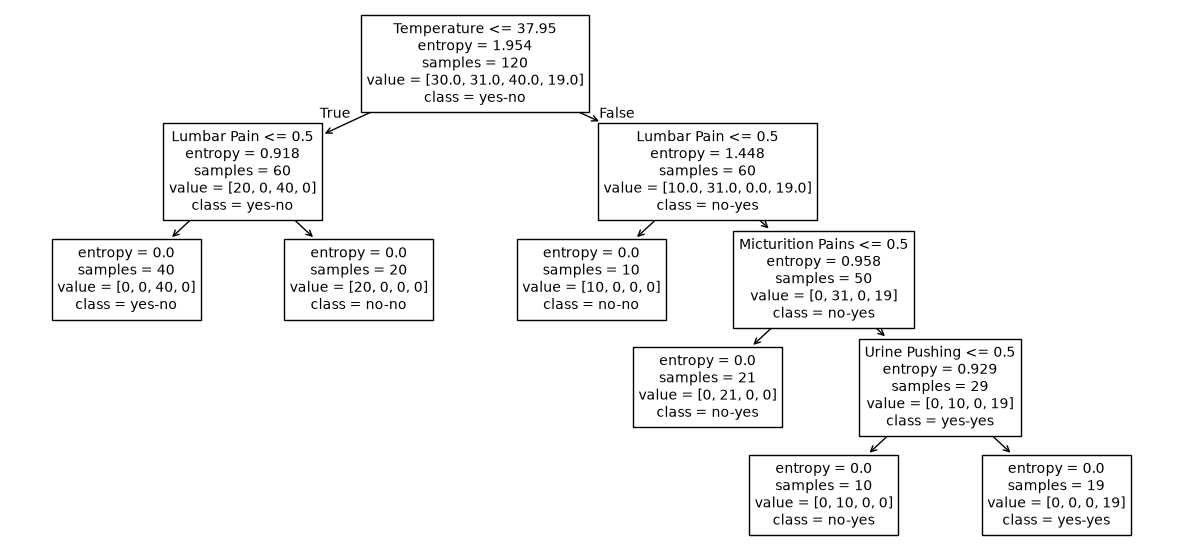

In [3]:
X = df.iloc[:, :6].replace({"no": 0, "yes": 1})
y = df["Bladder Inflammation"] + "-" + df["Nephritis"]

dt = DecisionTreeClassifier(criterion = "entropy", random_state = 1)
dt.fit(X, y)

plt.figure(figsize = (15,7))
plot_tree(dt, feature_names = X.columns, class_names = dt.classes_)
plt.show()

### (c) Convert the decision rules

In [4]:
def tree_to_pseudo(tree, feature_names):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] for i in tree.tree_.feature]
    value = tree.tree_.value
    
    def recurse(left, right, threshold, features, node, depth = 0):
        indent = " " * depth
        if (threshold[node] != -2):
            print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
            if left[node] != -1:
                recurse (left, right, threshold, features, left[node], depth+1)
                print(indent,"} else {")
                if right[node] != -1:
                    recurse (left, right, threshold, features, right[node], depth+1)
                print(indent,"}")
        else:
            print(indent,"return " + str(tree.classes_[value[node][0].argmax()]))
    recurse(left, right, threshold, features, 0)

tree_to_pseudo(dt, list(X.columns))

 if ( Temperature <= 37.95000076293945 ) {
  if ( Lumbar Pain <= 0.5 ) {
   return yes-no
  } else {
   return no-no
  }
 } else {
  if ( Lumbar Pain <= 0.5 ) {
   return no-no
  } else {
   if ( Micturition Pains <= 0.5 ) {
    return no-yes
   } else {
    if ( Urine Pushing <= 0.5 ) {
     return no-yes
    } else {
     return yes-yes
    }
   }
  }
 }


### (d) Cost-complexity pruning

In [5]:
path = dt.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas

dts = []

for alpha in path.ccp_alphas:
    dt1 = DecisionTreeClassifier(criterion = "entropy", ccp_alpha = alpha, random_state = 1)
    dt1.fit(X, y)
    dts.append(dt1)

pd.DataFrame({
    "alpha": path.ccp_alphas, 
    "leaves": [dt1.get_n_leaves() for dt1 in dts], 
    "accuracy": [dt1.score(X, y) for dt1 in dts]})

,alpha,leaves,accuracy
0,0.000000,6,1.000000
1,0.199592,4,0.841667
2,0.325011,3,0.758333
3,0.459148,2,0.591667
4,0.770426,1,0.333333


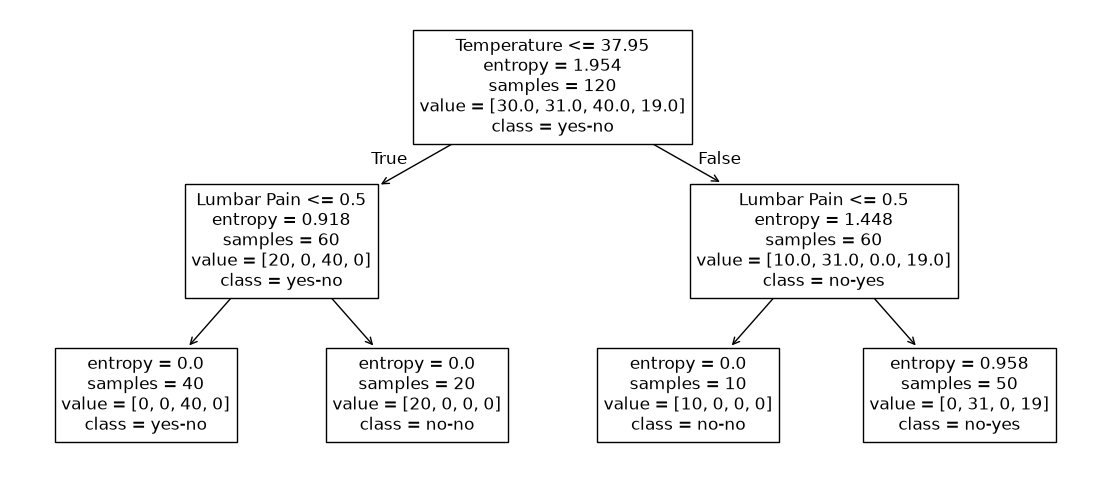

In [6]:
pruned = dts[1]

plt.figure(figsize = (14,6))
plot_tree(pruned, feature_names = X.columns, class_names = pruned.classes_)
plt.show()

In [7]:
tree_to_pseudo(pruned, list(X.columns))

 if ( Temperature <= 37.95000076293945 ) {
  if ( Lumbar Pain <= 0.5 ) {
   return yes-no
  } else {
   return no-no
  }
 } else {
  if ( Lumbar Pain <= 0.5 ) {
   return no-no
  } else {
   return no-yes
  }
 }


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [8]:
df = pd.read_csv("../data/communities.data", na_values = "?", header = None)

with open("../data/communities.names") as c:
    columns = [line.split()[1] for line in c if line.strip().startswith("@attribute")]
df.columns = columns

train = df.iloc[:1495]
test = df.iloc[1495:]

X_train = train.iloc[:, 5:-1]       # Ignore first 5 non-predictive columns
X_test = test.iloc[:, 5:-1]

y_train = train.iloc[:, -1]
y_test = test.iloc[:, -1]

### (b) Missing values

In [9]:
di_mean = X_train.mean()

X_train = X_train.fillna(di_mean)
X_test = X_test.fillna(di_mean)

### (c) Plot a correlation matrix

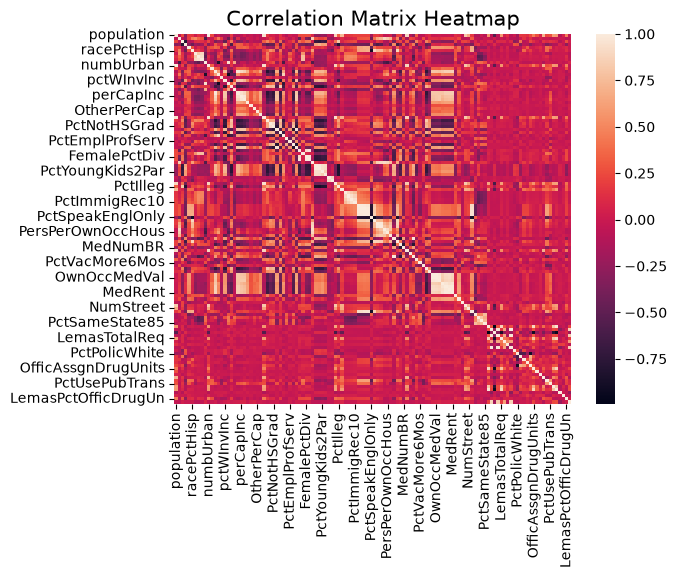

In [10]:
X = pd.concat([X_train, X_test])
y = pd.concat([y_train, y_test])

sns.heatmap(X.corr())
plt.title("Correlation Matrix Heatmap", fontsize = 15)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [11]:
cv = X.std() / X.mean()
print(cv)

population             2.203503
householdsize          0.353298
racepctblack           1.410920
racePctWhite           0.323782
racePctAsian           1.359162
                         ...   
PolicOperBudg          0.701202
LemasPctPolicOnPatr    0.120471
LemasGangUnitDeploy    0.360299
LemasPctOfficDrugUn    2.555266
PolicBudgPerPop        0.343782
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

In [12]:
high_cv_features = cv.nlargest(11)
print(high_cv_features)

NumStreet              4.407702
NumInShelters          3.485481
NumIlleg               2.994196
NumImmig               2.900497
LemasPctOfficDrugUn    2.555266
NumUnderPov            2.304970
population             2.203503
numbUrban              2.001744
HousVacant             1.958780
LandArea               1.678031
racePctHisp            1.614278
dtype: float64


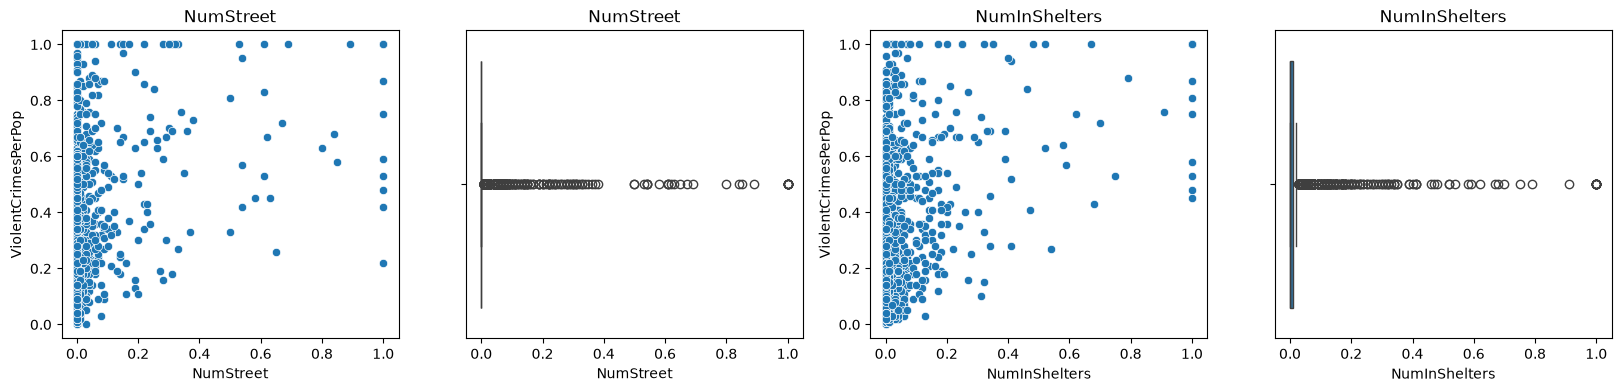

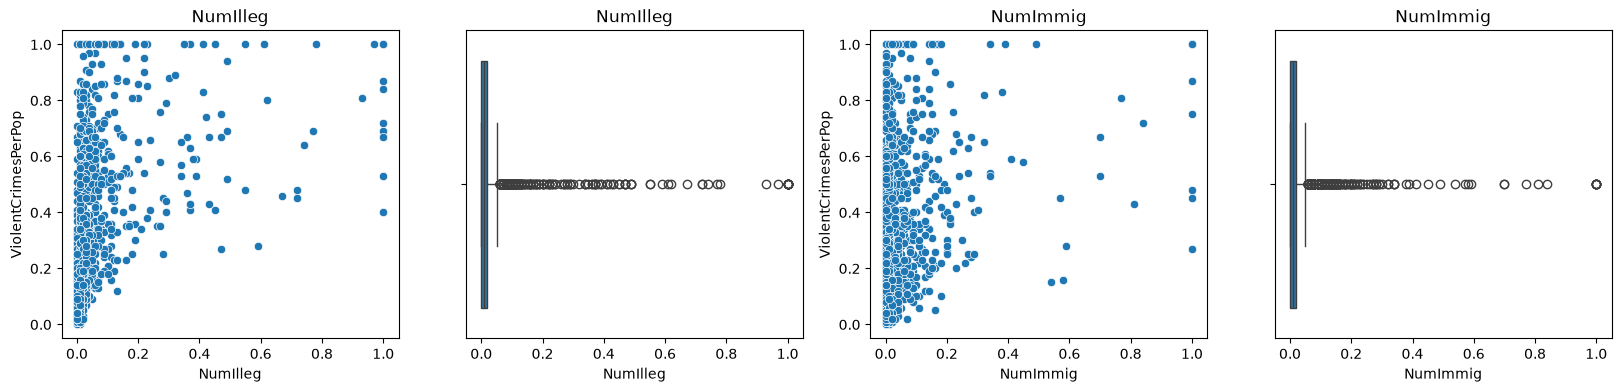

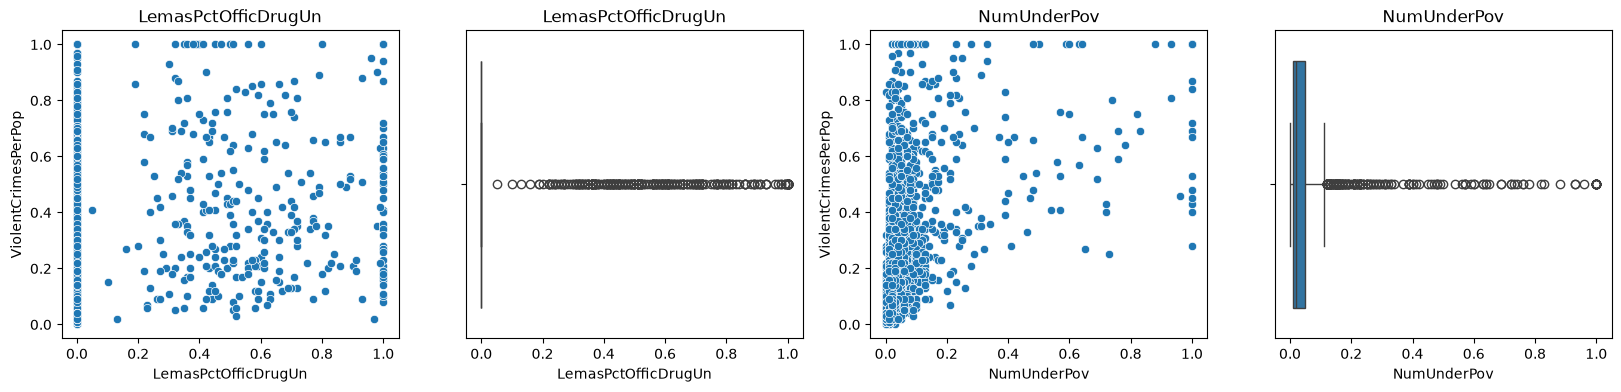

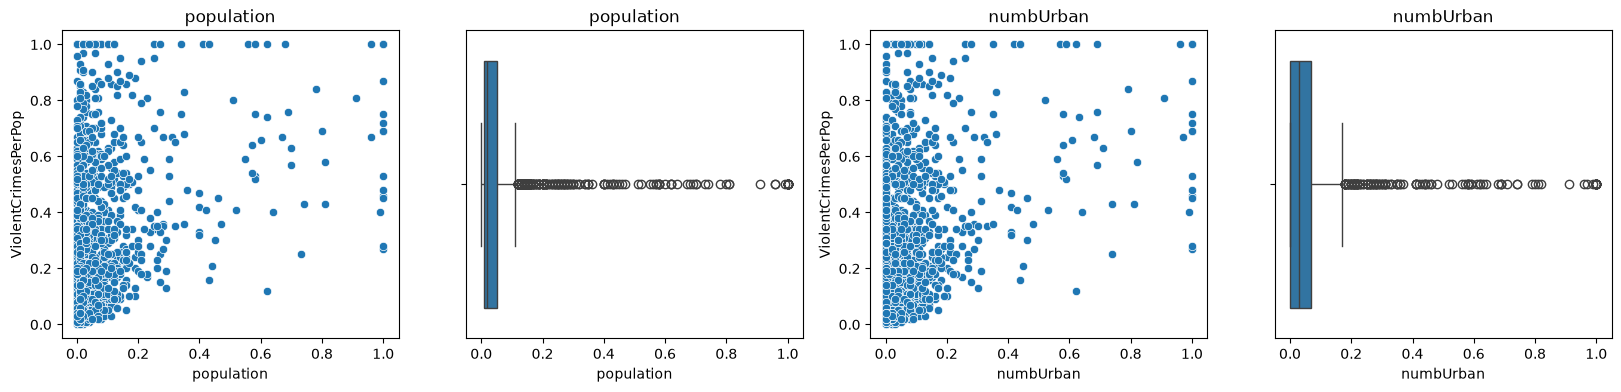

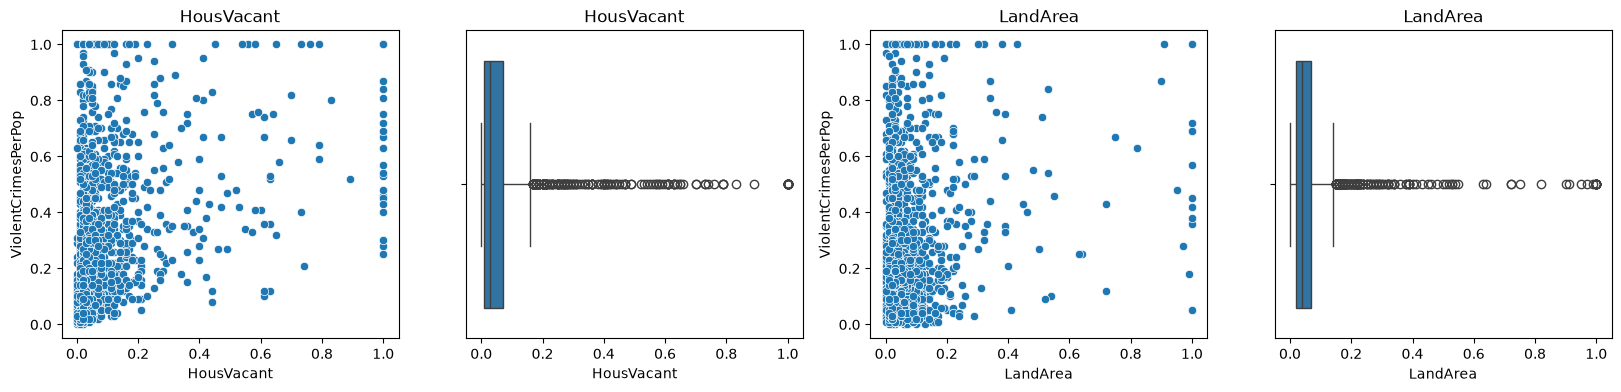

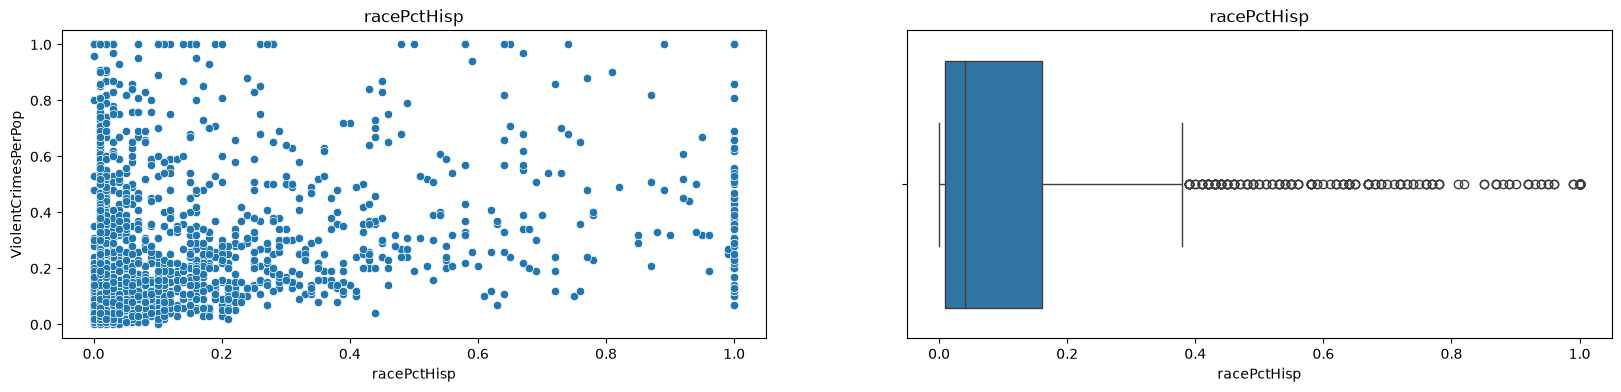

In [13]:
for i in range(0, len(high_cv_features), 2):
    fts = high_cv_features.index[i:i + 2]
    fig, axes = plt.subplots(1, 2*len(fts), figsize = (20, 4))

    for g, ft in enumerate(fts):
        sns.scatterplot(x = X[ft], y = y, ax = axes[2 * g])
        sns.boxplot(x = X[ft], ax = axes[2 * g + 1])

        axes[2 * g].set_title(ft)
        axes[2 * g + 1].set_title(ft)
    
    plt.show()

-   No, we cannot draw conclusions about significance of these features just by looking at the scatterplots because the data points are very scattered. Some features appear to show a positive relationship with the dependent variable but it is difficult to see clear trends

### (f) Fit a linear model

In [14]:
linear = LinearRegression()
linear.fit(X_train, y_train)

y_pred_linear = linear.predict(X_test)

print("linear test error:", round(mean_squared_error(y_test, y_pred_linear), 5))

linear test error: 0.01814


### (g) Fit a ridge regression model

In [15]:
ridge = RidgeCV(scoring = "neg_mean_squared_error" )
ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)

print("ridge test error:", round(mean_squared_error(y_test, y_pred_ridge), 5))
print("best ridge alpha:", ridge.alpha_)

ridge test error: 0.01773
best ridge alpha: 1.0


### (h) Fit a LASSO model

In [16]:
# Non standardized 
lasso = LassoCV()
lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

print("lasso test error:", round(mean_squared_error(y_test, y_pred_lasso), 5))
print("best lasso alpha:", round(lasso.alpha_, 5))
print("selected features:", X_train.columns[lasso.coef_ != 0].tolist())

lasso test error: 0.01776
best lasso alpha: 0.00012
selected features: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'P

c:\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.752930e-03, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
c:\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.011361e-02, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(


In [17]:
# Standardized
scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.fit_transform(X_test)

lasso_sc = LassoCV()
lasso_sc.fit(X_train_sc, y_train)

y_pred_lasso_sc = lasso_sc.predict(X_test_sc)

print("lasso scaled test error:", round(mean_squared_error(y_test, y_pred_lasso_sc), 5))
print("best lasso alpha:", round(lasso_sc.alpha_, 5))
print("selected features:", X_train.columns[lasso_sc.coef_ != 0].tolist())

lasso scaled test error: 0.01799
best lasso alpha: 0.00076
selected features: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSw

c:\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.826702e-03, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
c:\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.021131e-02, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
c:\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.981167e-03, tolerance: 6.746e-03
  mo

-   Lasso without standardization MSE: 0.01776
-   Lasso with standardization MSE: 0.01799
-   Lasso without standardization had a slightly lower test error than Lasso with standardization, suggesting that standardization did not improve model performance

### (i) Fit a PCR model

In [18]:
pcr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("linear", LinearRegression())
])

search_m = GridSearchCV(
    pcr,
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    scoring = "neg_mean_squared_error"
)

search_m.fit(X_train, y_train)

y_pred_pcr = search_m.predict(X_test)

print("pcr test error:", round(mean_squared_error(y_test, y_pred_pcr), 5))
print("best M:", search_m.best_params_["pca__n_components"])

pcr test error: 0.01839
best M: 95


### (j) Fit a boosting tree

In [19]:
bst = XGBRegressor()

search_a = GridSearchCV(
    bst,
    {"reg_alpha": [0.1, 1, 10]},
    scoring = "neg_mean_squared_error"

)

search_a.fit(X_train, y_train)

y_pred_bst = search_a.predict(X_test)

print("boost test error:", round(mean_squared_error(y_test, y_pred_bst), 5))
print("best alpha:", search_a.best_params_["reg_alpha"])

boost test error: 0.01775
best alpha: 1


### References
-   https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
-   https://xgboost.readthedocs.io/en/latest/python/python_api.html?utm_source=chatgpt.com
-   https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python